In [1]:
# Data manipulation
import os
os.environ["OMP_NUM_THREADS"] = "1"
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
df = pd.read_csv("Mall_Customers.csv")
# Display the first 5 rows
print(df.head())

# Check the number of rows and columns
print("Dataset shape:", df.shape)

# Check column names and data types
print(df.info())



   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40
Dataset shape: (200, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB
None


In [4]:
# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# Statistical summary
print(df.describe())


Missing values:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Duplicate rows: 0
       CustomerID         Age  Annual Income (k$)  Spending Score (1-100)
count  200.000000  200.000000          200.000000              200.000000
mean   100.500000   38.850000           60.560000               50.200000
std     57.879185   13.969007           26.264721               25.823522
min      1.000000   18.000000           15.000000                1.000000
25%     50.750000   28.750000           41.500000               34.750000
50%    100.500000   36.000000           61.500000               50.000000
75%    150.250000   49.000000           78.000000               73.000000
max    200.000000   70.000000          137.000000               99.000000


In [5]:
print("Minimum values:")
print(df[["Age", "Annual Income (k$)",
          "Spending Score (1-100)"]].min())

print("\nMaximum values:")
print(df[["Age", "Annual Income (k$)",
          "Spending Score (1-100)"]].max())

print("\nData types:")
print(df.dtypes)

Minimum values:
Age                       18
Annual Income (k$)        15
Spending Score (1-100)     1
dtype: int64

Maximum values:
Age                        70
Annual Income (k$)        137
Spending Score (1-100)     99
dtype: int64

Data types:
CustomerID                 int64
Gender                    object
Age                        int64
Annual Income (k$)         int64
Spending Score (1-100)     int64
dtype: object


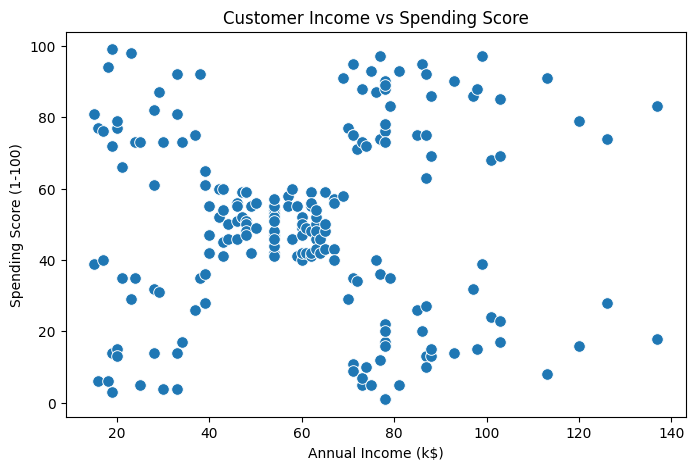

In [6]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    s=70
)

plt.title("Customer Income vs Spending Score")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.show()

In [7]:
features = ["Annual Income (k$)", "Spending Score (1-100)"]

X = df[features]

print("Selected features:")
print(X.head())

print("\nMissing values:")
print(X.isnull().sum())

print("\nData shape:", X.shape)

Selected features:
   Annual Income (k$)  Spending Score (1-100)
0                  15                      39
1                  15                      81
2                  16                       6
3                  16                      77
4                  17                      40

Missing values:
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Data shape: (200, 2)


In [8]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Scaled data:")
print(X_scaled[:5])

Scaled data:
[[-1.73899919 -0.43480148]
 [-1.73899919  1.19570407]
 [-1.70082976 -1.71591298]
 [-1.70082976  1.04041783]
 [-1.66266033 -0.39597992]]


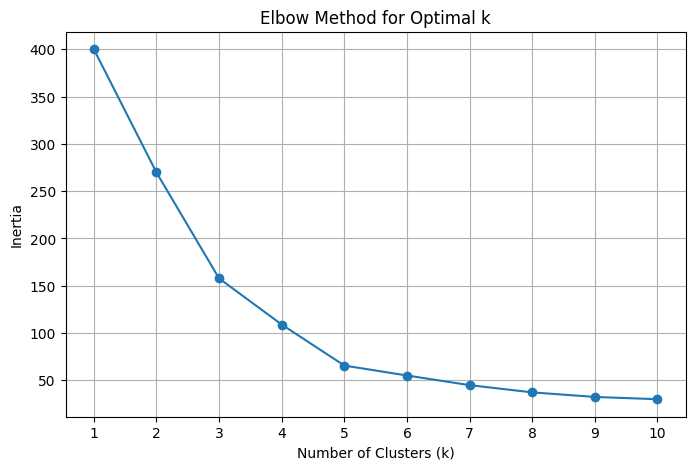

In [9]:
inertia = []
k_values = range(1, 11)

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(k_values, inertia, marker="o")

plt.title("Elbow Method for Optimal k")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.xticks(k_values)
plt.grid(True)
plt.show()

In [10]:
for k, value in zip(k_values, inertia):
    print(f"k = {k}: Inertia = {value:.2f}")

k = 1: Inertia = 400.00
k = 2: Inertia = 269.69
k = 3: Inertia = 157.70
k = 4: Inertia = 108.92
k = 5: Inertia = 65.57
k = 6: Inertia = 55.06
k = 7: Inertia = 44.86
k = 8: Inertia = 37.23
k = 9: Inertia = 32.39
k = 10: Inertia = 29.98


In [11]:
for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)

    print(f"k = {k}: Silhouette Score = {score:.3f}")

k = 2: Silhouette Score = 0.321
k = 3: Silhouette Score = 0.467
k = 4: Silhouette Score = 0.494
k = 5: Silhouette Score = 0.555
k = 6: Silhouette Score = 0.540
k = 7: Silhouette Score = 0.528
k = 8: Silhouette Score = 0.455
k = 9: Silhouette Score = 0.457
k = 10: Silhouette Score = 0.443


In [12]:
# Create the final K-Means model
kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)


df["Cluster"] = kmeans.fit_predict(X_scaled)

print("Customers in each cluster:")
print(df["Cluster"].value_counts().sort_index())

Customers in each cluster:
Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64


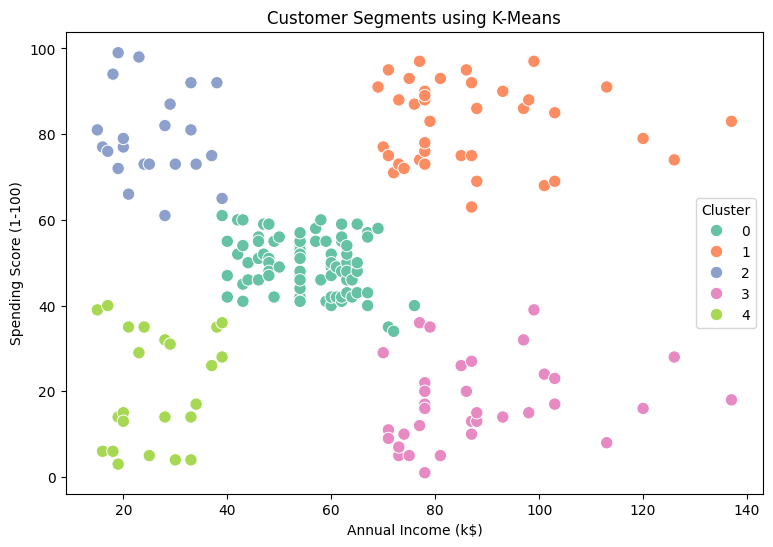

In [13]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Cluster",
    palette="Set2",
    s=80
)

plt.title("Customer Segments using K-Means")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend(title="Cluster")
plt.show()

In [14]:
cluster_summary = df.groupby("Cluster")[
    [
        "Age",
        "Annual Income (k$)",
        "Spending Score (1-100)"
    ]
].mean().round(2)

print(cluster_summary)

           Age  Annual Income (k$)  Spending Score (1-100)
Cluster                                                   
0        42.72               55.30                   49.52
1        32.69               86.54                   82.13
2        25.27               25.73                   79.36
3        41.11               88.20                   17.11
4        45.22               26.30                   20.91


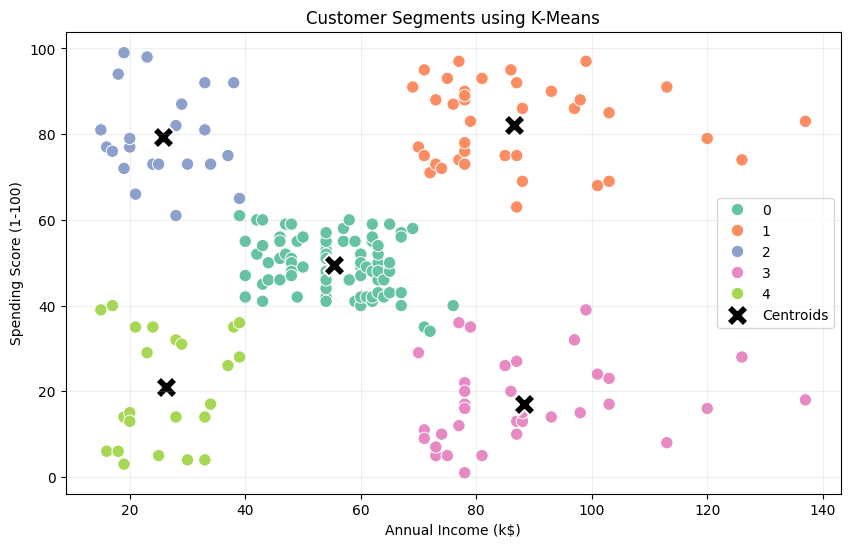

In [15]:
# Get cluster centers and convert them to original scale
centers = scaler.inverse_transform(kmeans.cluster_centers_)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Cluster",
    palette="Set2",
    s=80
)

# Plot cluster centers
plt.scatter(
    centers[:, 0],
    centers[:, 1],
    marker="X",
    s=250,
    color="black",
    edgecolor="white",
    linewidth=1.5,
    label="Centroids"
)

plt.title("Customer Segments using K-Means")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

# Conclusion

In this project, K-Means clustering was used to segment 200 mall customers based on their annual income and spending score.

The data was explored and checked for missing values, duplicates, and reasonable value ranges. The selected features were standardized using "StandardScaler" before applying K-Means.

The Elbow Method and Silhouette Score were used to help select the number of clusters. A model with 5 clusters achieved a Silhouette Score of 0.555, the highest among the tested values.

The cluster analysis revealed five customer segments with different income and spending patterns. These segments can help the mall develop more targeted marketing strategies, such as loyalty programs for high-spending customers and suitable promotional offers for customers with lower spending scores.

Overall, this project demonstrates how unsupervised machine learning can be used to discover customer groups and support data-driven marketing decisions.

In [16]:
import joblib

joblib.dump(kmeans, "kmeans_model.pkl")
joblib.dump(scaler, "scaler.pkl")

print("Model and scaler saved successfully!")

Model and scaler saved successfully!
